**Loading the Dataset**

In [2]:
import pandas as pd
df=pd.read_csv(r"C:\Users\gemin\OneDrive\varunijoshi24_1785871442080346.csv")
print(df.head())

  Country                              Year  From Date    To Date Category  \
0   India  Financial Year (Apr - Mar), 2021  01-Apr-21  31-Dec-21  Digital   
1   India  Financial Year (Apr - Mar), 2021  01-Apr-21  31-Dec-21  Digital   
2   India  Financial Year (Apr - Mar), 2021  01-Apr-21  31-Dec-21  Digital   
3   India  Financial Year (Apr - Mar), 2021  01-Apr-21  31-Dec-21  Digital   
4   India  Financial Year (Apr - Mar), 2021  01-Apr-21  31-Dec-21  Digital   

   Language     Region  \
0  Assamese     Mumbai   
1  Assamese    Kolkata   
2  Assamese    Chennai   
3  Assamese  Hyderabad   
4  Assamese  Bengaluru   

   Indian Feature Films Certified By The Board (UOM:Number), Scaling Factor:1  
0                                                NaN                           
1                                                NaN                           
2                                                NaN                           
3                                                NaN  

**EDA**

In [3]:
print("shape","\n",df.shape)
print("-------"*2)
print("dtypes","\n",df.dtypes)
print("-------"*2)
print("missing values","\n",df.isnull().sum())

shape 
 (1899, 8)
--------------
dtypes 
 Country                                                                        object
Year                                                                           object
From Date                                                                      object
To Date                                                                        object
Category                                                                       object
Language                                                                       object
Region                                                                         object
Indian Feature Films Certified By The Board (UOM:Number), Scaling Factor:1    float64
dtype: object
--------------
missing values 
 Country                                                                          0
Year                                                                             0
From Date                                                 

In [4]:
df['From Date'] = pd.to_datetime(df['From Date'], format='%d-%b-%y')
df['To Date'] = pd.to_datetime(df['To Date'], format='%d-%b-%y')
print(df.dtypes)

Country                                                                               object
Year                                                                                  object
From Date                                                                     datetime64[ns]
To Date                                                                       datetime64[ns]
Category                                                                              object
Language                                                                              object
Region                                                                                object
Indian Feature Films Certified By The Board (UOM:Number), Scaling Factor:1           float64
dtype: object


In [5]:
col = 'Indian Feature Films Certified By The Board (UOM:Number), Scaling Factor:1'

df[col] = df[col].fillna(df[col].median())
print(df.isnull().sum())

Country                                                                       0
Year                                                                          0
From Date                                                                     0
To Date                                                                       0
Category                                                                      0
Language                                                                      0
Region                                                                        0
Indian Feature Films Certified By The Board (UOM:Number), Scaling Factor:1    0
dtype: int64


In [6]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


**outliers**

In [7]:
col = 'Indian Feature Films Certified By The Board (UOM:Number), Scaling Factor:1'
Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[(df[col] < lower_limit) | (df[col] > upper_limit)]

print("Number of outliers:", len(outliers))
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("outliers:",outliers)

Number of outliers: 377
Lower limit: 3.0
Upper limit: 3.0
outliers:      Country                              Year  From Date    To Date Category  \
8      India  Financial Year (Apr - Mar), 2021 2021-04-01 2021-12-31  Digital   
12     India  Financial Year (Apr - Mar), 2021 2021-04-01 2021-12-31  Digital   
13     India  Financial Year (Apr - Mar), 2021 2021-04-01 2021-12-31  Digital   
22     India  Financial Year (Apr - Mar), 2021 2021-04-01 2021-12-31  Digital   
28     India  Financial Year (Apr - Mar), 2021 2021-04-01 2021-12-31  Digital   
...      ...                               ...        ...        ...      ...   
1881   India  Financial Year (Apr - Mar), 2018 2018-04-01 2018-12-31    Video   
1890   India  Financial Year (Apr - Mar), 2018 2018-04-01 2018-12-31    Video   
1892   India  Financial Year (Apr - Mar), 2018 2018-04-01 2018-12-31    Video   
1894   India  Financial Year (Apr - Mar), 2018 2018-04-01 2018-12-31    Video   
1895   India  Financial Year (Apr - Mar),

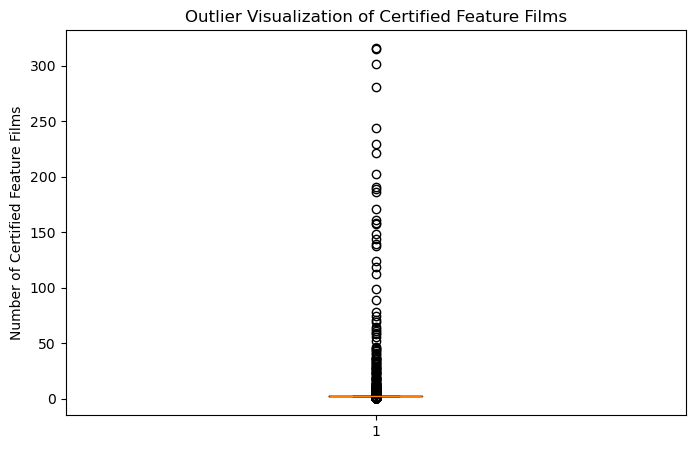

In [8]:
import matplotlib.pyplot as plt

col = 'Indian Feature Films Certified By The Board (UOM:Number), Scaling Factor:1'

plt.figure(figsize=(8, 5))
plt.boxplot(df[col])
plt.ylabel('Number of Certified Feature Films')
plt.title('Outlier Visualization of Certified Feature Films')
plt.show()

**Feature Selection**

In [9]:
print(df['Country'].unique())

['India']


In [10]:
df.drop('Country', axis=1, inplace=True)

In [11]:
print(df['Category'].value_counts())
print(df['Language'].value_counts().head(20))
print(df['Region'].value_counts().head(20))
print(df.shape)

Category
Digital    1440
Video       459
Name: count, dtype: int64
Language
Gujarati                63
Bhojpuri                63
Bengali                 63
Kannada                 63
Hindi                   63
Marathi                 63
Tamil                   63
Punjabi                 63
Odia                    63
Malayalam               63
English                 54
Telugu                  54
Tulu                    45
Manipuri                45
Hinglish                45
Haryanvi                36
Chhattisgarhi           36
Assamese                36
Rajasthani              36
Hindi Partly English    36
Name: count, dtype: int64
Region
Mumbai                211
Kolkata               211
Chennai               211
Hyderabad             211
Bengaluru             211
Thiruvananthapuram    211
Delhi                 211
Cuttack               211
Guwahati              211
Name: count, dtype: int64
(1899, 7)


In [12]:
X = df[['Year', 'Category', 'Language', 'Region']]

y = df[
    'Indian Feature Films Certified By The Board (UOM:Number), Scaling Factor:1'
]

In [13]:
X_encoded = pd.get_dummies(
    X,
    columns=['Category', 'Language', 'Region'],
    dtype=int
)

print(X_encoded.head())

                               Year  Category_Digital  Category_Video  \
0  Financial Year (Apr - Mar), 2021                 1               0   
1  Financial Year (Apr - Mar), 2021                 1               0   
2  Financial Year (Apr - Mar), 2021                 1               0   
3  Financial Year (Apr - Mar), 2021                 1               0   
4  Financial Year (Apr - Mar), 2021                 1               0   

   Language_Assamese  Language_Awadhi  Language_Banjara  Language_Beary  \
0                  1                0                 0               0   
1                  1                0                 0               0   
2                  1                0                 0               0   
3                  1                0                 0               0   
4                  1                0                 0               0   

   Language_Beary (Byari)  Language_Beary With English Sub-Titles  \
0                       0                

In [15]:
# Check the columns and their data types
print(X.dtypes)

# Find columns containing text
print(X.select_dtypes(include=['object']).columns)

Year        object
Category      int8
Language      int8
Region        int8
dtype: object
Index(['Year'], dtype='object')


In [18]:
# Convert categorical columns into numeric codes
X['Category'] = X['Category'].astype('category').cat.codes
X['Language'] = X['Language'].astype('category').cat.codes
X['Region'] = X['Region'].astype('category').cat.codes

# If the financial year column exists, encode it too
X['Year'] = X['Year'].astype('category').cat.codes
print(X['Year'])

0       3
1       3
2       3
3       3
4       3
       ..
1894    0
1895    0
1896    0
1897    0
1898    0
Name: Year, Length: 1899, dtype: int8


In [19]:
print(X.select_dtypes(include=['object']).columns.tolist())
for col in X.columns:
    if X[col].dtype == 'object':
        print(col, X[col].head())

[]


In [20]:
print(X.dtypes)
print("X shape:", X.shape)
print("X contains strings:", X.map(lambda v: isinstance(v, str)).any().any())

Year        int8
Category    int8
Language    int8
Region      int8
dtype: object
X shape: (1899, 4)
X contains strings: False


In [21]:
print(y.dtype)
print(y.head())
print(y.map(lambda v: isinstance(v, str)).any())

float64
0    3.0
1    3.0
2    3.0
3    3.0
4    3.0
Name: Indian Feature Films Certified By The Board (UOM:Number), Scaling Factor:1, dtype: float64
False


In [22]:
mi_scores = mutual_info_regression(
    X,
    y,
    discrete_features=[False, True, True, True],
    random_state=42
)

print(mi_scores)

[0.01770274 0.00481886 0.07331443 0.0768613 ]


In [24]:
mi_df = pd.DataFrame({
    'Feature': X.columns,
    'MI Score': mi_scores
}).sort_values(by='MI Score', ascending=False)

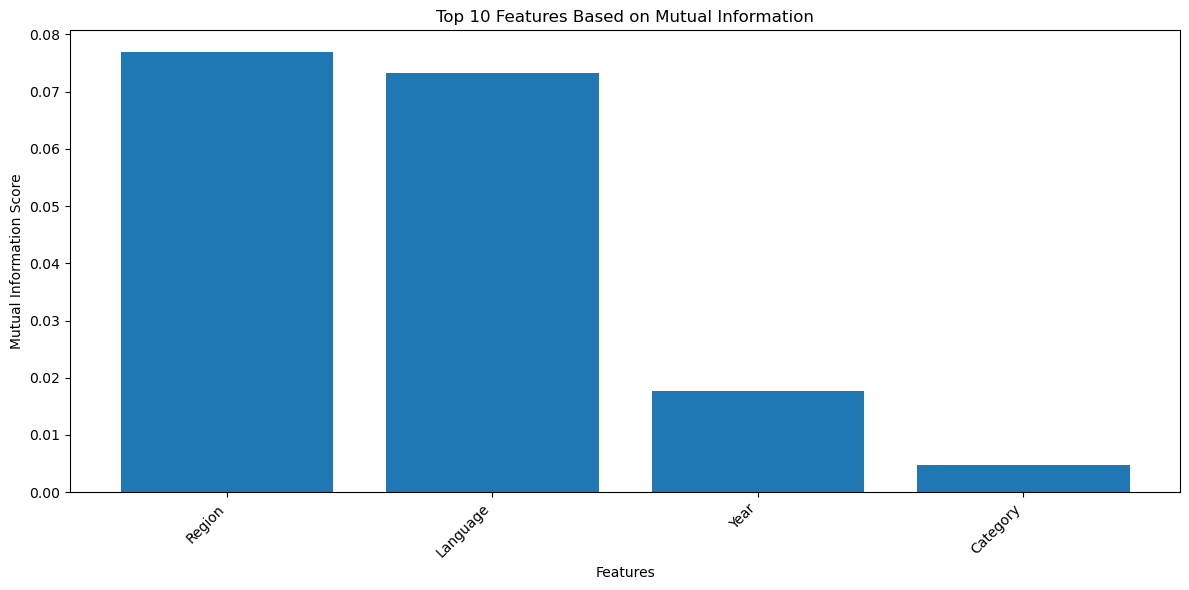

In [25]:
import matplotlib.pyplot as plt

top_mi = mi_df.head(10)

plt.figure(figsize=(12, 6))
plt.bar(top_mi['Feature'], top_mi['MI Score'])

plt.xlabel('Features')
plt.ylabel('Mutual Information Score')
plt.title('Top 10 Features Based on Mutual Information')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Model Builidng**

In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1519, 95)
Testing data: (380, 95)


In [28]:
print(X_train.dtypes)
print(X_train.head())

Year                         object
Category_Digital              int64
Category_Video                int64
Language_Assamese             int64
Language_Awadhi               int64
                              ...  
Region_Guwahati               int64
Region_Hyderabad              int64
Region_Kolkata                int64
Region_Mumbai                 int64
Region_Thiruvananthapuram     int64
Length: 95, dtype: object
                                  Year  Category_Digital  Category_Video  \
1005  Financial Year (Apr - Mar), 2019                 1               0   
1793  Financial Year (Apr - Mar), 2018                 0               1   
1774  Financial Year (Apr - Mar), 2018                 0               1   
339   Financial Year (Apr - Mar), 2020                 1               0   
824   Financial Year (Apr - Mar), 2019                 1               0   

      Language_Assamese  Language_Awadhi  Language_Banjara  Language_Beary  \
1005                  0                0   

In [29]:
import pandas as pd

for data in [X_train, X_test]:
    data['Year'] = (
        data['Year']
        .astype(str)
        .str.extract(r'(\d{4})')
        .astype(int)
    )

In [30]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model training completed!")

y_pred = model.predict(X_test)

print("Actual vs Predicted:")
print(pd.DataFrame({
    'Actual Films': y_test.values,
    'Predicted Films': y_pred
}).head(10))

Model training completed!
Actual vs Predicted:
   Actual Films  Predicted Films
0           3.0        13.780693
1           3.0         4.773862
2           3.0         3.875223
3           5.0        18.658881
4           3.0         2.835825
5          34.0        20.660100
6           3.0         0.626161
7           3.0         4.167693
8           3.0        10.744153
9           3.0         7.836012


In [31]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R² Score:", r2)

MAE: 8.487555614906467
MSE: 762.385783493022
RMSE: 27.61133433018082
R² Score: 0.09756488623185544


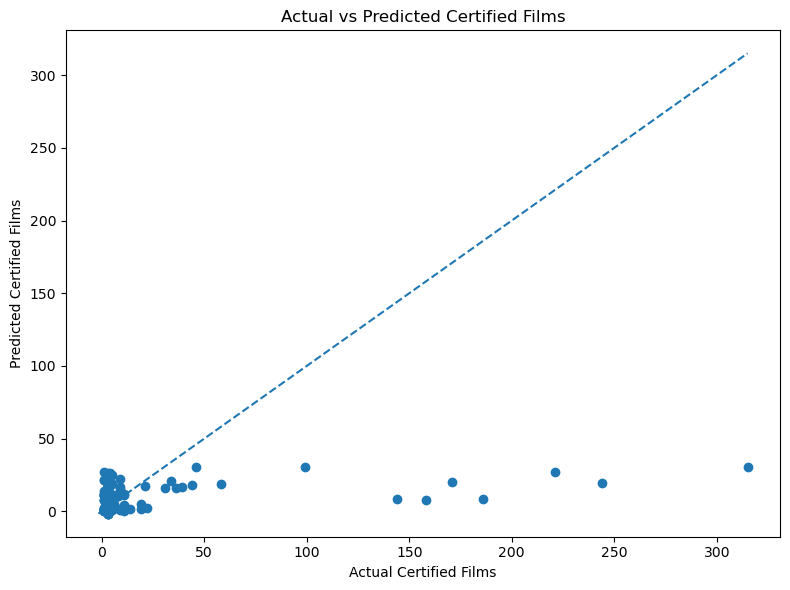

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

# Perfect prediction line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

plt.xlabel('Actual Certified Films')
plt.ylabel('Predicted Certified Films')
plt.title('Actual vs Predicted Certified Films')
plt.tight_layout()
plt.show()